# **Project Name**    - Netflix Movies and TV Shows Clustering

##### **Project Type** - Unsupervised ML
##### **Contribution** - Varsha S (Individual)

# **Project Summary -**

This project applies **unsupervised machine learning** to the Netflix Movies and TV Shows catalogue. The objective is to explore similarities between titles using their descriptions and catalogue metadata, including genre/category, content type, and rating. The workflow includes data understanding, data cleaning, exploratory data analysis, hypothesis testing, text preprocessing, TF-IDF feature extraction, dimensionality reduction for the hierarchical model, and comparison of three clustering algorithms: K-Means, MiniBatch K-Means, and Agglomerative Clustering.

The resulting groups are intended for **exploratory catalogue analysis** and may help content teams inspect thematic segments. They are not official Netflix categories, personalized recommendations, or evidence of viewer preferences. The dataset is a historical catalogue snapshot and does not contain viewing histories, engagement, licensing costs, or revenue data. Cluster quality is therefore assessed with internal clustering metrics, cluster-size checks, and representative-title interpretation rather than supervised prediction accuracy.


This project applies unsupervised machine learning to the Netflix Movies and TV Shows catalog. The objective is to identify groups of titles with similar genres, descriptions, and content metadata. These clusters can support catalog exploration, thematic collections, and content-planning analysis.

The project follows this structure: business understanding, data understanding, data wrangling, exploratory data analysis, feature engineering, preprocessing, model implementation, model evaluation, hyperparameter tuning, explainability, future work, and conclusion.

Important: clustering is an unsupervised task. There is no target column or ground-truth cluster label, so the project uses internal clustering metrics and human interpretation rather than classification accuracy or regression metrics.

# **GitHub Link -**


https://github.com/Varsha-Salimon/Netflix-Movies-and-TV-Shows-Clustering

# **Problem Statement**

The Netflix catalogue contains movies and TV shows with descriptive metadata such as title type, release year, country, content rating, genres, and synopsis. Reviewing thousands of titles manually makes it difficult to identify recurring themes and similarities across the catalogue.

The objective of this project is to use **unsupervised machine learning** to group Netflix titles with similar textual and catalogue characteristics. The project combines descriptions with selected metadata, converts the resulting text into TF-IDF features, and compares K-Means, MiniBatch K-Means, and Agglomerative Clustering.

The intended outcome is an exploratory segmentation that can help analysts inspect catalogue themes and content groupings. Since the dataset does not include user viewing behaviour, engagement, revenue, or licensing data, the clusters are not personalized recommendations and cannot establish audience preferences or commercial performance.

Netflix contains movies and TV shows spanning many genres, languages, release periods, and themes. The goal is to group similar titles based on available catalog metadata and synopsis text, then interpret those groups to discover patterns in the catalog.

Business objective: create meaningful exploratory content segments that help catalog and editorial teams browse similar titles and understand catalog composition. The model does not claim to represent official Netflix categories or individual viewer preferences.

### Business Context
The supplied project brief describes this as a Netflix catalog snapshot collected from Flixable and discusses changes in the mix of movies and TV shows. The analysis therefore examines the catalog's genre and country coverage and compares title types over release years and dates added to Netflix. The data is a historical snapshot; it should not be treated as a current view of Netflix's catalog.

# **General Guidelines** : -


1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.


# ***Let's Begin !***


## ***1. Know Your Data***


### Dataset Description

The dataset contains Netflix title metadata such as title type, title name, director, cast, country, date added, release year, maturity rating, duration, genre/category tags, and synopsis. The CSV is downloaded from the Google Drive file link supplied for this project, so it does not need to be uploaded manually each time.



### Importing Libraries

In [67]:
import os
import sys
import subprocess
import warnings
warnings.filterwarnings("ignore")

# Install gdown only if it is not already available in the Colab runtime.
try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import ParameterGrid
import joblib

from nltk.stem import SnowballStemmer

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.



The notebook imports pandas, NumPy, Matplotlib, Seaborn, scikit-learn, and Joblib for analysis, visualization, clustering, and model persistence.


### Dataset Loading

In [68]:
# This downloads it automatically into the current Colab runtime on each fresh session.
# No manual file upload is required.
FILE_ID = "1EUIqDXyn4XvV28mBV0HM0SKPqkUx7gEW"
CSV_PATH = "/content/netflix_movies_tv_shows.csv"
DRIVE_URL = f"https://drive.google.com/uc?id={FILE_ID}"

if not os.path.exists(CSV_PATH):
    downloaded_path = gdown.download(DRIVE_URL, CSV_PATH, quiet=False, fuzzy=True)
    if downloaded_path is None:
        raise RuntimeError(
            "Could not download the CSV. Check that the Google Drive file is shared "
            "with 'Anyone with the link' as Viewer, then rerun this cell."
        )

df = pd.read_csv(CSV_PATH)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


### Dataset First View


In [69]:
display(df.head())


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


### Dataset Rows & Columns count


In [70]:
print("Dataset rows:", df.shape[0])
print("Dataset columns:", df.shape[1])


Dataset rows: 7787
Dataset columns: 12


### Dataset Information


In [71]:
print("\nData types and non-null counts:")
df.info()


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


#### Duplicate Values


In [72]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


#### Missing Values/Null Values


In [73]:
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))


,Missing values
director,2389
cast,718
country,507
date_added,10
rating,7
title,0
show_id,0
type,0
release_year,0
duration,0


### What did you know about your dataset?



The dataset contains Netflix catalog metadata for Movies and TV Shows. The description and category fields are useful for content-based clustering. There are no ground-truth cluster labels, so internal clustering metrics and cluster interpretation are used instead of supervised accuracy.

In [74]:
for column in df.columns:
    print(f"{column}: {df[column].nunique(dropna=True)} unique non-null values")


show_id: 7787 unique non-null values
type: 2 unique non-null values
title: 7787 unique non-null values
director: 4049 unique non-null values
cast: 6831 unique non-null values
country: 681 unique non-null values
date_added: 1565 unique non-null values
release_year: 73 unique non-null values
rating: 14 unique non-null values
duration: 216 unique non-null values
listed_in: 492 unique non-null values
description: 7769 unique non-null values


## ***2. Understanding Your Variables***


In [75]:
# Dataset Columns
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [76]:
# Dataset Describe

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,3%,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

In [77]:
variable_description = pd.DataFrame({
    "Variable": [
        "show_id", "type", "title", "director", "cast", "country",
        "date_added", "release_year", "rating", "duration", "listed_in", "description"
    ],
    "Description": [
        "Unique identifier for a title",
        "Whether the title is a Movie or TV Show",
        "Name of the movie or TV show",
        "Director or directors",
        "Actors and contributors",
        "Country or countries of production",
        "Date the title was added to Netflix",
        "Original release year",
        "Maturity/content rating",
        "Movie runtime or TV-show season count",
        "Genres or catalog categories",
        "Short synopsis of the title"
    ]
})
display(variable_description)

,Variable,Description
0,show_id,Unique identifier for a title
1,type,Whether the title is a Movie or TV Show
2,title,Name of the movie or TV show
3,director,Director or directors
4,cast,Actors and contributors
5,country,Country or countries of production
6,date_added,Date the title was added to Netflix
7,release_year,Original release year
8,rating,Maturity/content rating
9,duration,Movie runtime or TV-show season count


### Check Unique Values for each variable.


In [78]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percent", ascending=False)
display(missing_summary)
print("Exact duplicate rows:", df.duplicated().sum())
if "show_id" in df.columns:
    print("Duplicate show_id values:", df["show_id"].duplicated().sum())

,Missing Count,Missing Percent
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
duration,0,0.00


Exact duplicate rows: 0
Duplicate show_id values: 0


### Understanding the Business Context

Catalog segmentation can help content teams explore similar titles, identify genre concentrations, and generate hypotheses for editorial collections. The dataset does not contain user watch histories, engagement, licensing costs, or satisfaction, so it cannot establish what viewers prefer or prove a financial impact.

## 3. ***Data Wrangling***

### Data Wrangling Code



The cleaning cells below create a working copy, remove duplicates, parse dates, and prepare fields for analysis.

In [79]:
data = df.copy()

# Remove exact duplicate rows and duplicate show IDs (if any).
data = data.drop_duplicates()
if "show_id" in data.columns:
    data = data.drop_duplicates(subset=["show_id"])
data = data.reset_index(drop=True)

# Parse date_added and derive year_added. Invalid/missing dates remain NaT/NaN.
data["date_added_parsed"] = pd.to_datetime(data["date_added"], errors="coerce")
data["year_added"] = data["date_added_parsed"].dt.year

# Preserve missingness in descriptive metadata; use "Unknown" only for text fields
# that will be combined into the text representation.
text_fields = ["type", "title", "director", "cast", "country", "rating",
               "duration", "listed_in", "description"]
for col in text_fields:
    data[col] = data[col].fillna("Unknown").astype(str).str.strip()

# Keep release_year numeric and missing where unavailable; do not fabricate a year.
data["release_year"] = pd.to_numeric(data["release_year"], errors="coerce")

print("Shape after cleaning:", data.shape)
print("Exact duplicates remaining:", data.duplicated().sum())
print("Duplicate show_id values:",
      data["show_id"].duplicated().sum() if "show_id" in data.columns else "N/A")
print("\nMissing values after field-aware handling:")
display(data.isna().sum().to_frame("missing_count"))

Shape after cleaning: (7787, 14)
Exact duplicates remaining: 0
Duplicate show_id values: 0

Missing values after field-aware handling:


,missing_count
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,0


#### Outlier Treatment

Outlier treatment is not the same as in a supervised numeric prediction task. Release years and durations can contain unusual but valid catalog values. We inspect their ranges and avoid automatically deleting titles solely because their values are rare.

In [80]:
display(data[["release_year"]].describe())
print("Earliest release year:", data["release_year"].min())
print("Latest release year:", data["release_year"].max())
print("\nDuration examples:")
display(data[["type", "duration"]].head(10))

,release_year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


Earliest release year: 1925
Latest release year: 2021

Duration examples:


,type,duration
0,TV Show,4 Seasons
1,Movie,93 min
2,Movie,78 min
3,Movie,80 min
4,Movie,123 min
5,TV Show,1 Season
6,Movie,95 min
7,Movie,119 min
8,Movie,118 min
9,Movie,143 min


### What all manipulations have you done and insights you found?


Rows are deduplicated, selected missing text/category values are handled explicitly, dates are parsed, and derived date fields support catalog-addition analysis. Valid older releases are retained rather than removed as outliers.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***


### Chart - 1


**Chart name:** Count Plot

**Chart focus:** Movies vs TV Shows

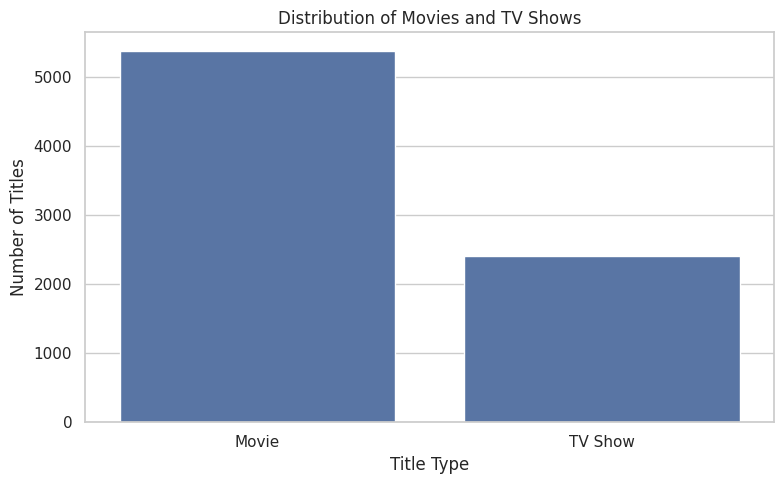

,title_count
type,
Movie,5377
TV Show,2410


In [81]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="type", order=data["type"].value_counts().index)
plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Title Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()
display(data["type"].value_counts().to_frame("title_count"))


#### 1. Why did you pick the specific chart?



A count plot is suitable for comparing the number of titles across the two categorical title types.

#### 2. What is/are the insight(s) found from the chart?


The chart shows that **Movies are more common** than TV Shows. The dataset contains **5,377 Movies** and **2,410 TV Shows**, a difference of **2,967 titles**. Movies therefore represent the larger share of this historical catalogue snapshot. This describes the composition of the supplied dataset, not current Netflix availability.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


The split helps describe catalog composition and can guide further analysis. It does not, by itself, show demand or profitability.

### Chart - 2



**Chart name:** Line Chart

**Chart focus:** Titles by Release Year


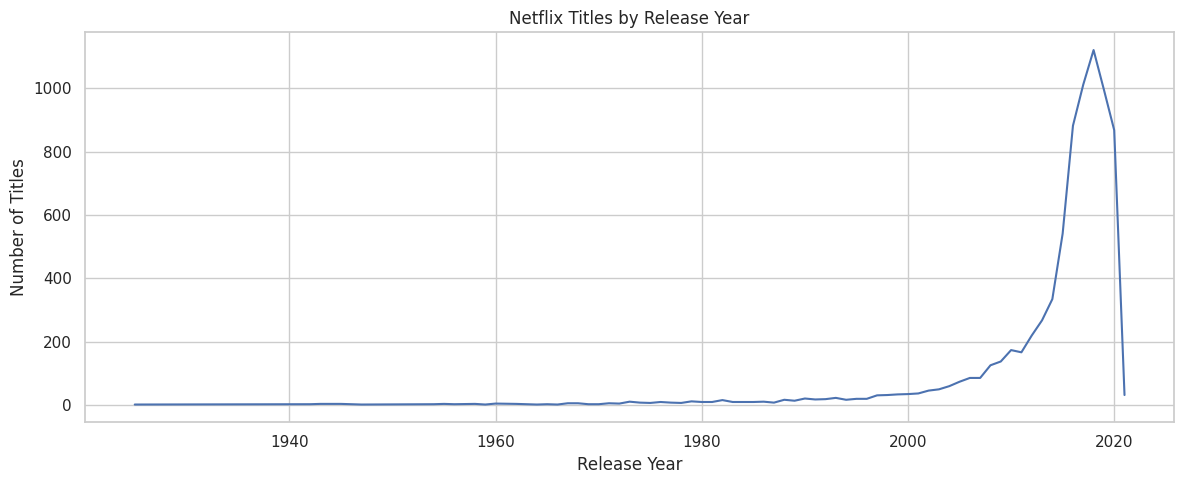

In [82]:
year_counts = data["release_year"].dropna().astype(int).value_counts().sort_index()
plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

#### 1. Why did you pick the specific chart?


A line chart shows how the number of catalog titles varies by original release year.


#### 2. What is/are the insight(s) found from the chart?


The release-year distribution is concentrated in more recent years, particularly from **2015 onward** (5,451 titles in this dataset). The chart has relatively few titles in the earliest years and a stronger concentration in the later years. This reflects the catalogue snapshot and its coverage; it should not be interpreted as a complete measure of global film and television production. The recorded release years range from 1925 to 2021.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


Release-year distribution can help content teams explore catalog eras, but it does not measure viewership or demand.

### Chart - 3



**Chart name:** Horizontal Bar Chart

**Chart focus:** Content Available Across Countries


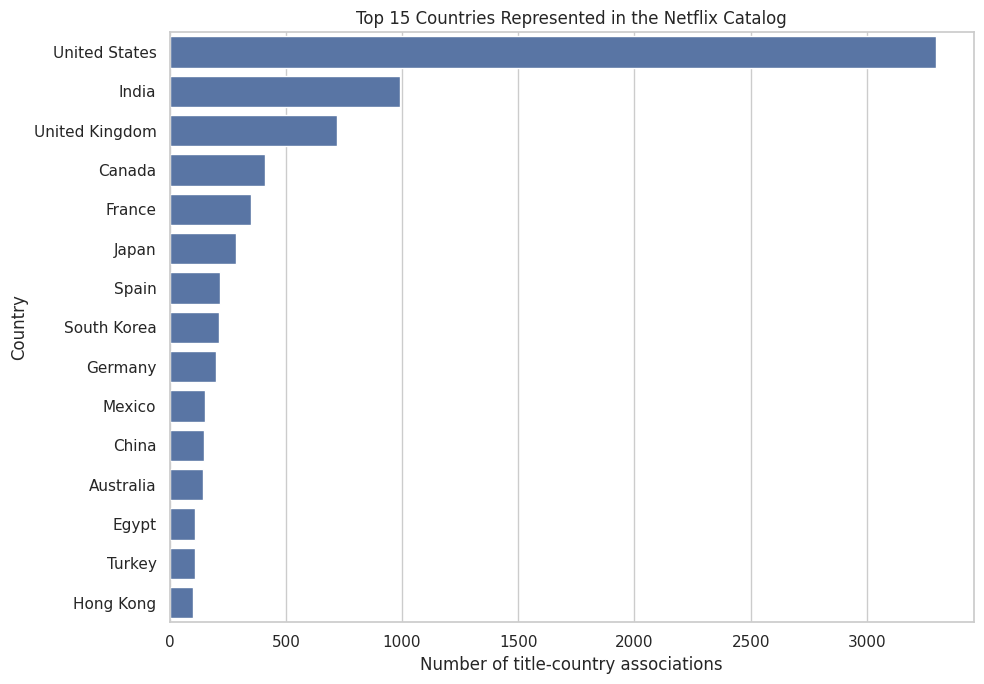

,title_country_count
country,
United States,3296
India,990
United Kingdom,722
Canada,412
France,349
Japan,287
Spain,215
South Korea,212
Germany,199


In [83]:
country_counts = (
    data["country"].replace("Unknown", np.nan).dropna()
    .str.split(", ").explode().str.strip()
    .replace("", np.nan).dropna().value_counts().head(15)
)
plt.figure(figsize=(10, 7))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top 15 Countries Represented in the Netflix Catalog")
plt.xlabel("Number of title-country associations")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
display(country_counts.to_frame("title_country_count"))

#### 1. Why did you pick the specific chart?


A horizontal bar chart compares the countries with the largest number of titles. Since some records list multiple countries, each country is split into an individual category for this analysis.


#### 2. What is/are the insight(s) found from the chart?


The most represented production countries are **United States (3,296), India (990), United Kingdom (722), Canada (412), France (349)**. Country values can contain multiple countries for one title, so each title is counted once for every country listed. The counts therefore represent country-title associations, not mutually exclusive title totals. Missing country information is not treated as a country.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


Country distribution describes catalog coverage and can help teams identify geographic concentration or underrepresented regions. It does not independently measure local demand or profitability.

### Chart - 4



**Chart name:** Line Chart

**Chart focus:** Movies vs TV Shows by Release Year


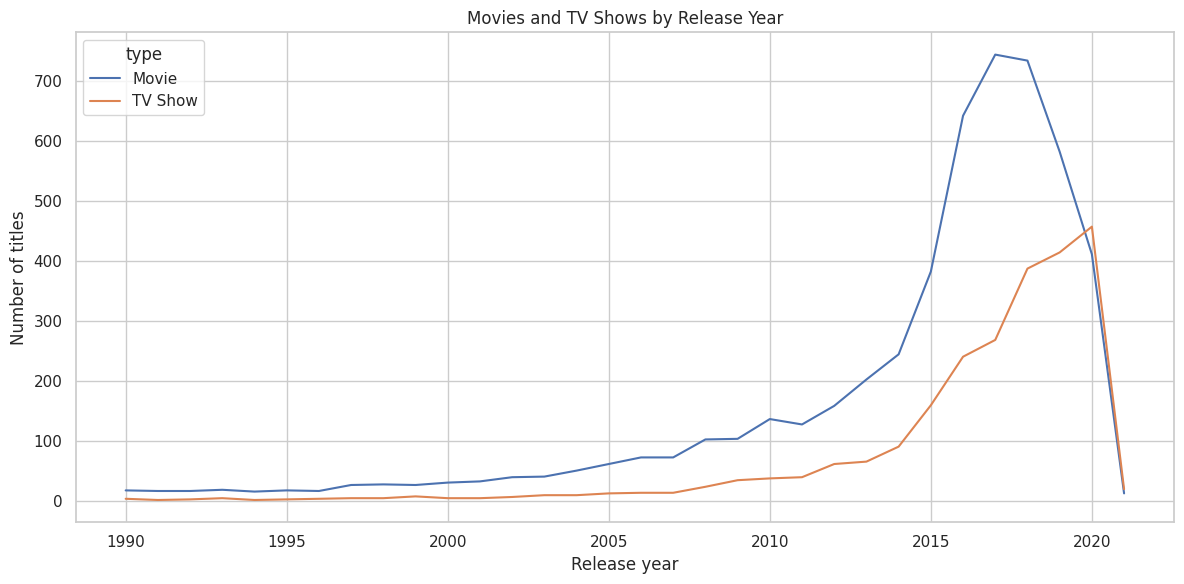

Title type,Movie,TV Show
Release-year period,,
Up to 2009,85.22,14.78
2010–2019,69.18,30.82
2020 onwards,47.05,52.95


In [84]:
type_year = (
    data.dropna(subset=["release_year"])
    .assign(release_year=lambda x: x["release_year"].astype(int))
    .groupby(["release_year", "type"]).size()
    .unstack(fill_value=0)
    .sort_index()
)
for col in ["Movie", "TV Show"]:
    if col not in type_year.columns:
        type_year[col] = 0
ax = type_year[["Movie", "TV Show"]].loc[1990:].plot(figsize=(12, 6))
ax.set_title("Movies and TV Shows by Release Year")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of titles")
plt.tight_layout()
plt.show()

# Compare title-type shares for two periods using the available release-year metadata.
valid_year = data.dropna(subset=["release_year"]).copy()
valid_year["release_year"] = valid_year["release_year"].astype(int)
periods = pd.cut(
    valid_year["release_year"],
    bins=[-np.inf, 2009, 2019, np.inf],
    labels=["Up to 2009", "2010–2019", "2020 onwards"]
)
period_mix = pd.crosstab(periods, valid_year["type"], normalize="index").mul(100).round(2)
display(period_mix.rename_axis("Release-year period").rename_axis(columns="Title type"))

#### 1. Why did you pick the specific chart?


A line chart compares annual counts for Movies and TV Shows and directly addresses whether the catalog's mix changes over release years.


#### 2. What is/are the insight(s) found from the chart?


Review the plotted trends and the recent-period table. State whether the share of TV Shows among titles rises in the selected recent period compared with the earlier period. This is a catalog-mix comparison, not proof of Netflix's business strategy or audience demand.


#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


The comparison helps analysts describe changes in catalog composition and ask follow-up questions about content strategy. It cannot establish why the composition changed without additional business data.

#### Additional Business Check: Titles Added to Netflix by Year
Release year describes when a title was originally released; date added describes when it entered the catalog. The latter is more directly relevant to checking changes in Netflix's catalog additions. Interpret this carefully because the dataset is a snapshot and may not capture all historical additions.

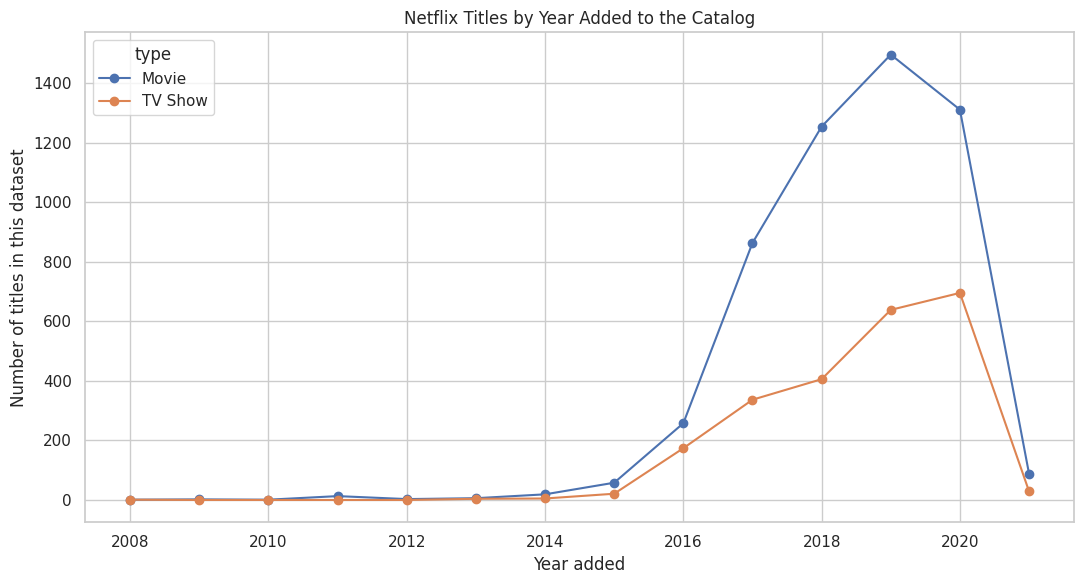

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,4
2014,19,5
2015,58,21
2016,258,174


In [85]:
added = data.dropna(subset=["date_added_parsed"]).copy()
added["year_added"] = added["date_added_parsed"].dt.year
added_counts = added.groupby(["year_added", "type"]).size().unstack(fill_value=0)
for col in ["Movie", "TV Show"]:
    if col not in added_counts.columns:
        added_counts[col] = 0
added_counts = added_counts[["Movie", "TV Show"]].sort_index()
ax = added_counts.plot(kind="line", marker="o", figsize=(11, 6))
ax.set_title("Netflix Titles by Year Added to the Catalog")
ax.set_xlabel("Year added")
ax.set_ylabel("Number of titles in this dataset")
plt.tight_layout()
plt.show()
display(added_counts)

### Chart - 5



**Chart name:** Horizontal Bar Chart

**Chart focus:** Most Common Genres


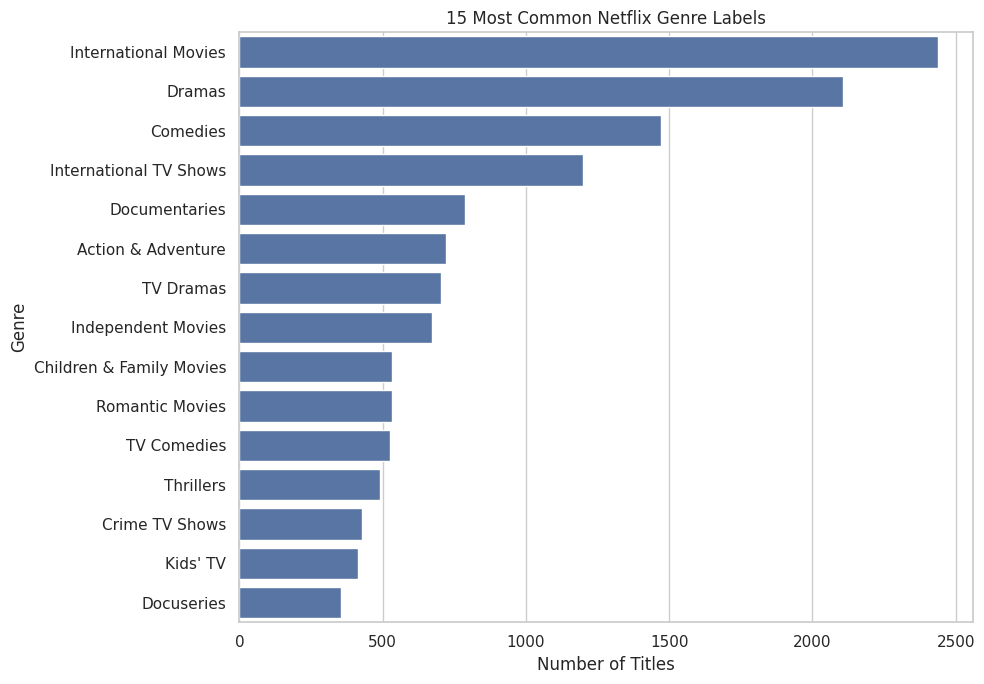

In [86]:
genre_counts = (
    data["listed_in"].replace("Unknown", np.nan).dropna()
    .str.split(", ").explode().value_counts().head(15)
)
plt.figure(figsize=(10, 7))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("15 Most Common Netflix Genre Labels")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

#### 1. Why did you pick the specific chart?


A horizontal bar chart clearly ranks the most frequent genre/category labels.


#### 2. What is/are the insight(s) found from the chart?


The most frequent genre/category labels are **International Movies (2,437), Dramas (2,106), Comedies (1,471), International TV Shows (1,199), Documentaries (786)**. These are catalogue labels, and a title can have multiple labels; consequently, the counts overlap and should not be added to estimate the number of unique titles. The prominence of international and drama-related labels suggests that these categories are important parts of this dataset's catalogue mix.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


Genre counts help describe catalog coverage and may reveal areas for deeper investigation. They are not evidence of audience demand.

### Chart - 6



**Chart name:** Horizontal Bar Chart

**Chart focus:** Distribution of Content Ratings


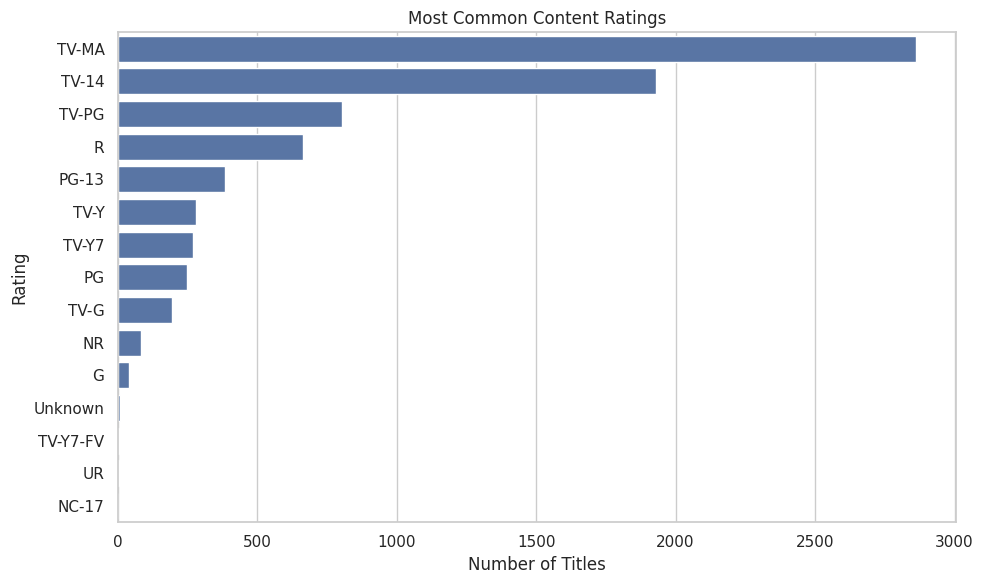

In [87]:
rating_counts = data["rating"].value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Most Common Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

#### 1. Why did you pick the specific chart?


A bar chart makes the most common maturity/content ratings easy to compare.


#### 2. What is/are the insight(s) found from the chart?


Use the plot to identify common ratings and any missing/unknown rating category.


#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


Rating distribution can help teams understand catalog suitability segments, but it does not indicate actual audience size.

### Chart - 7



**Chart name:** Horizontal Bar Chart

**Chart focus:** Missing Values by Column


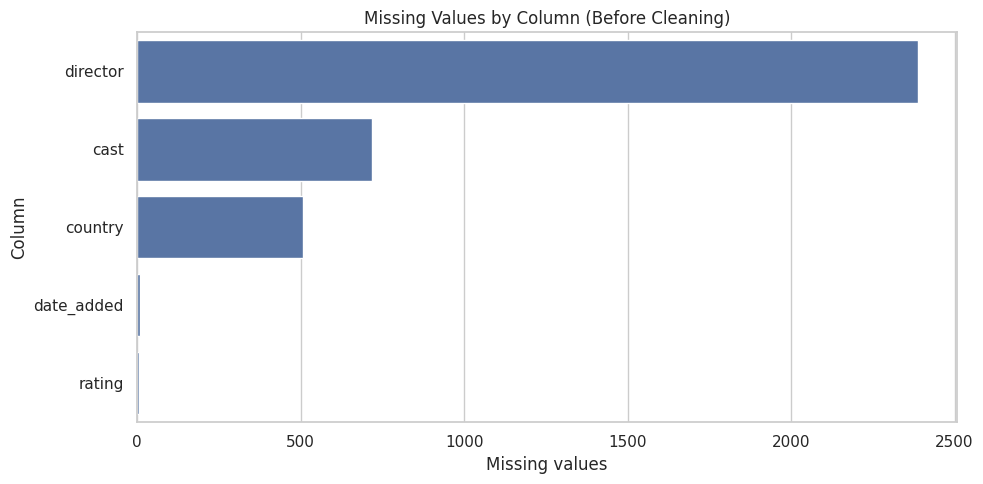

In [88]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]
if len(missing_counts):
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_counts.values, y=missing_counts.index)
    plt.title("Missing Values by Column (Before Cleaning)")
    plt.xlabel("Missing values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were detected in the original dataset.")

#### 1. Why did you pick the specific chart?


A bar chart makes data-quality gaps visible and helps prioritize preprocessing.


#### 2. What is/are the insight(s) found from the chart?


Use the output to name columns with the highest missing counts before cleaning.


#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.


Better data quality supports more reliable segmentation. Filling missing fields with placeholders preserves rows but also means missingness should be considered when interpreting results.

### Chart - 8



**Chart name:** Histograms


**Chart focus:** Distribution of title duration



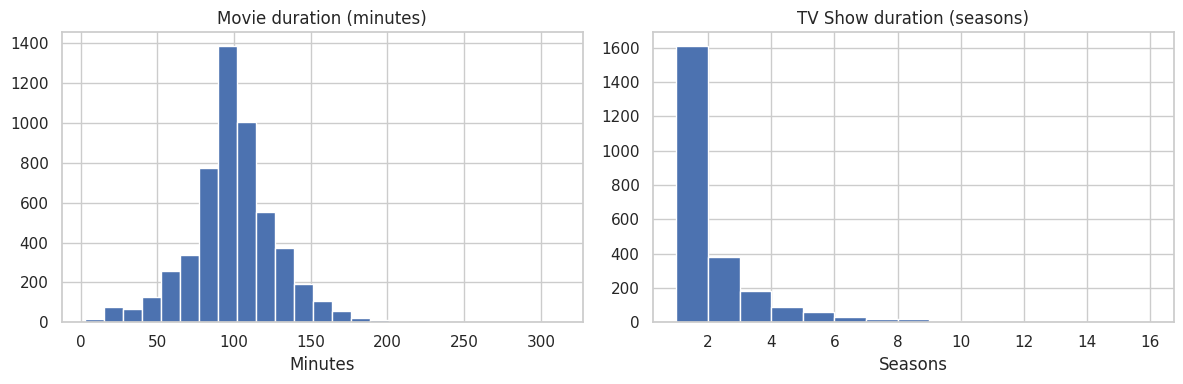

In [89]:
duration_split = data.copy()
duration_split["duration_num"] = pd.to_numeric(duration_split["duration"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
movie_duration = duration_split.loc[duration_split["type"].eq("Movie"), "duration_num"].dropna()
tv_duration = duration_split.loc[duration_split["type"].eq("TV Show"), "duration_num"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(movie_duration, bins=25); axes[0].set_title("Movie duration (minutes)"); axes[0].set_xlabel("Minutes")
axes[1].hist(tv_duration, bins=15); axes[1].set_title("TV Show duration (seasons)"); axes[1].set_xlabel("Seasons")
plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


Duration can differ by format, so Movies and TV Shows are plotted separately.



##### 2. What is/are the insight(s) found from the chart?


Use the generated distributions to inspect typical runtime and season-count ranges.



##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
This supports catalog-format analysis but does not directly measure popularity.


### Chart - 9



**Chart name:** Stacked Bar Chart

**Chart focus:** Content ratings by title type



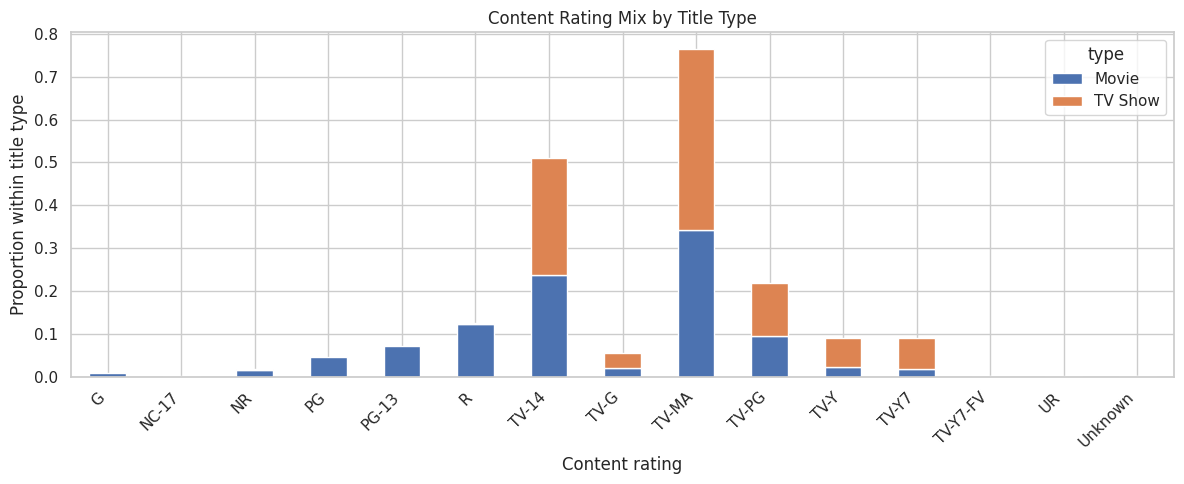

In [90]:
rating_type = pd.crosstab(data["rating"].fillna("Unknown"), data["type"], normalize="columns")
rating_type.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Content Rating Mix by Title Type"); plt.ylabel("Proportion within title type"); plt.xlabel("Content rating")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


A stacked bar chart compares rating mixes for Movies and TV Shows.



##### 2. What is/are the insight(s) found from the chart?



Compare the proportions of maturity ratings across title types.



##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
This can support audience and catalog classification, but is not evidence of viewing behavior.

### Chart - 10



**Chart name:** Horizontal Bar Chart

**Chart focus:** Top directors by number of titles



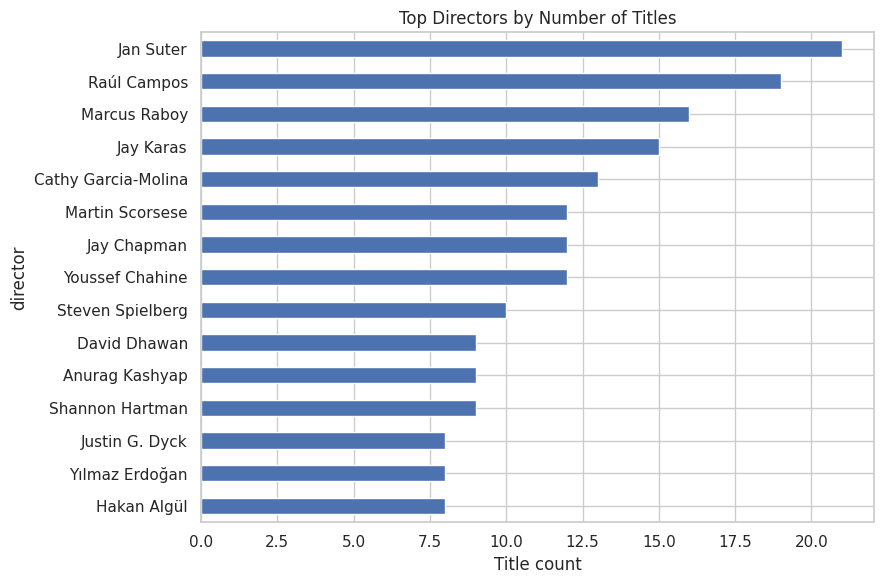

In [91]:
director_counts = data.loc[data["director"].notna() & data["director"].ne("Unknown"), "director"].str.split(", ").explode().value_counts().head(15).sort_values()
director_counts.plot(kind="barh", figsize=(9, 6)); plt.title("Top Directors by Number of Titles"); plt.xlabel("Title count"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


A horizontal bar chart makes director counts easy to compare.



##### 2. What is/are the insight(s) found from the chart?


The chart highlights directors with the most titles in this snapshot.




##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
Counts can inform catalog breadth analysis but do not indicate quality or profitability.

### Chart - 11



**Chart name:** Horizontal Bar Chart

**Chart focus:** Most frequent category labels



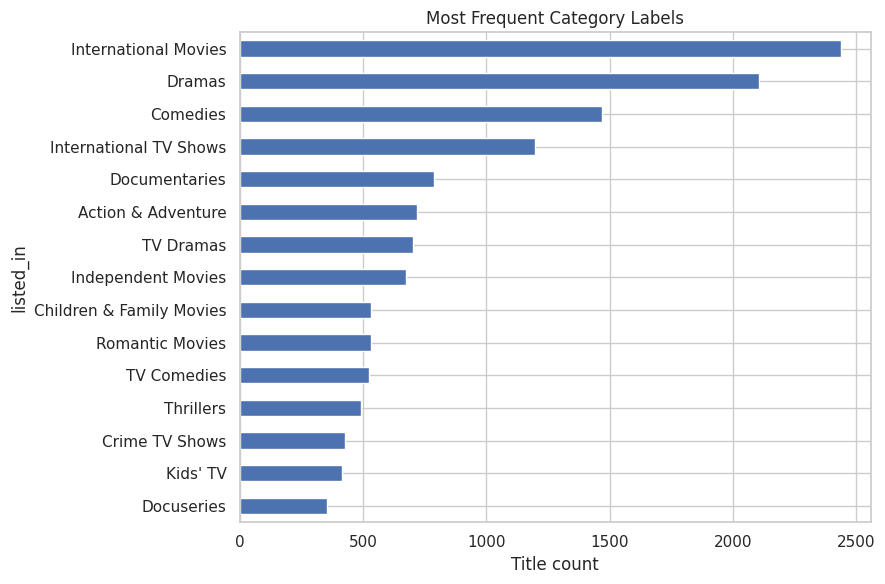

In [92]:
category_counts = data["listed_in"].dropna().astype(str).str.split(", ").explode().value_counts().head(15).sort_values()
category_counts.plot(kind="barh", figsize=(9, 6)); plt.title("Most Frequent Category Labels"); plt.xlabel("Title count"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


A horizontal bar chart ranks the most common listed-in category labels.




##### 2. What is/are the insight(s) found from the chart?


The chart reveals which category labels dominate the catalog.



##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
Category counts may help content planning, but do not measure profitability.

### Chart - 12



**Chart name:** Multi-Line Chart

**Chart focus:** Titles added by year and type



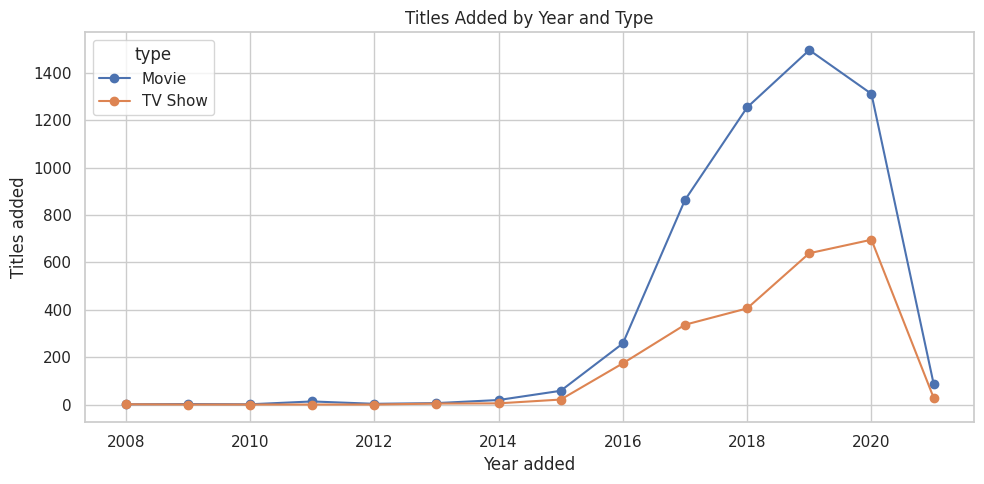

In [93]:
# Ensure the year-added feature exists in the main dataframe.
if "year_added" not in data.columns:
    if "date_added_parsed" not in data.columns:
        data["date_added_parsed"] = pd.to_datetime(data["date_added"], errors="coerce")
    data["year_added"] = data["date_added_parsed"].dt.year

added_type = (
    data.dropna(subset=["year_added"])
        .groupby(["year_added", "type"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
)

# Keep both title types visible, even if one has no observations in a year.
for title_type in ["Movie", "TV Show"]:
    if title_type not in added_type.columns:
        added_type[title_type] = 0
added_type = added_type[["Movie", "TV Show"]]

ax = added_type.plot(marker="o", figsize=(10, 5))
ax.set_title("Titles Added by Year and Type")
ax.set_xlabel("Year added")
ax.set_ylabel("Titles added")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


A line chart separates catalog additions by title type.



##### 2. What is/are the insight(s) found from the chart?


This chart describes when titles entered the catalog, not original release year.



##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
This supports catalog acquisition analysis, not direct audience-demand measurement.


### Chart - 13



**Chart name:** Histogram

**Chart focus:** Description length distribution



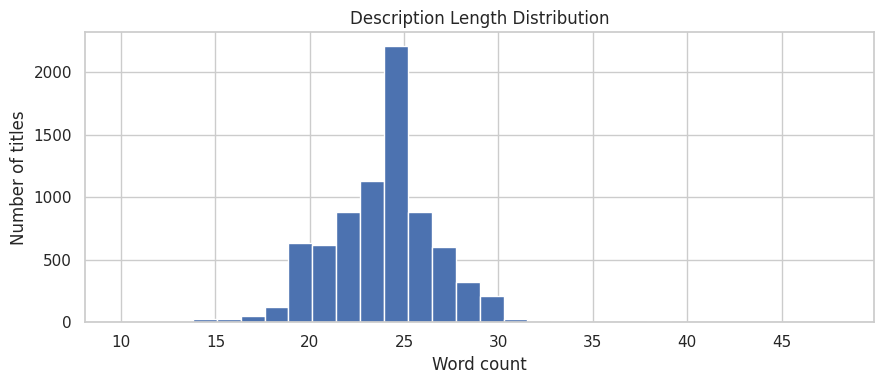

In [94]:
desc_lengths = data["description"].fillna("").astype(str).str.split().str.len()
plt.figure(figsize=(9, 4)); plt.hist(desc_lengths, bins=30); plt.title("Description Length Distribution"); plt.xlabel("Word count"); plt.ylabel("Number of titles"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


A histogram inspects synopsis length before text vectorization.



##### 2. What is/are the insight(s) found from the chart?



The output shows whether descriptions are mostly short or long.



##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
Description length can influence text representation and should be monitored.

### Chart - 14 - Correlation Heatmap

**Chart focus:** Correlation among numeric metadata



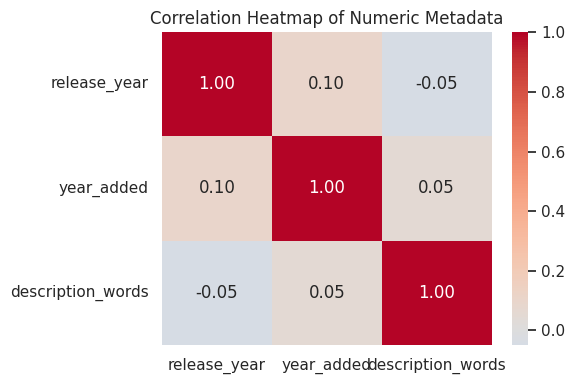

In [95]:
numeric_eda = pd.DataFrame(index=data.index)
numeric_eda["release_year"] = pd.to_numeric(data["release_year"], errors="coerce")
if "year_added" in data.columns: numeric_eda["year_added"] = pd.to_numeric(data["year_added"], errors="coerce")
numeric_eda["description_words"] = data["description"].fillna("").astype(str).str.split().str.len()
corr = numeric_eda.corr(numeric_only=True)
plt.figure(figsize=(6, 4)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f"); plt.title("Correlation Heatmap of Numeric Metadata"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?


A heatmap summarizes relationships among numeric metadata only.



##### 2. What is/are the insight(s) found from the chart?


Interpret correlations among release year, year added, and description length after viewing the matrix.




##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
This is descriptive analysis and does not replace semantic text similarity.

### Chart - 15 - Pair Plot



**Chart focus:** Pairwise numeric metadata patterns




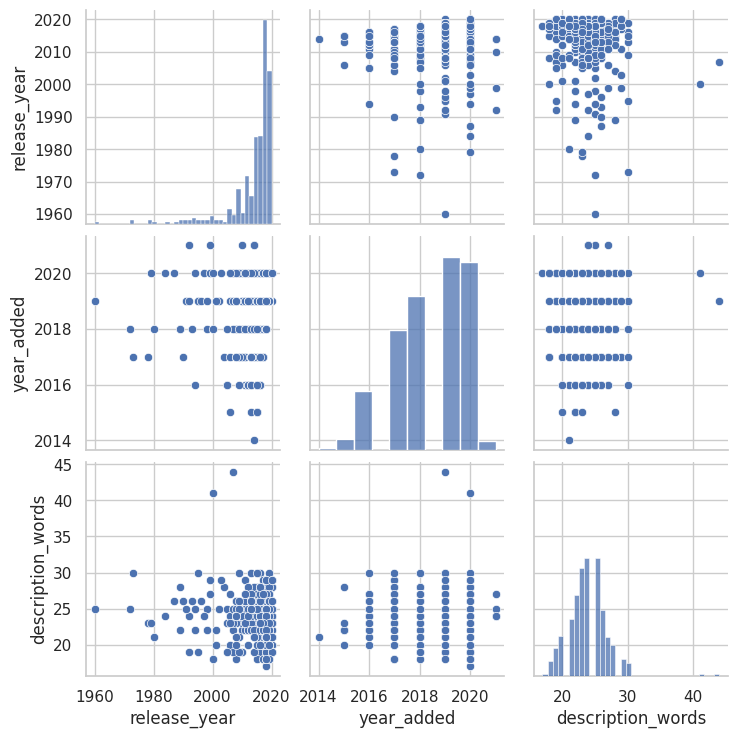

In [96]:
pair_data = numeric_eda.dropna()
if len(pair_data) > 1:
    pair_data = pair_data.sample(n=min(400, len(pair_data)), random_state=42)
    sns.pairplot(pair_data); plt.show()
else:
    print("Not enough complete numeric rows for a pair plot.")


##### 1. Why did you pick the specific chart?


A pair plot gives a compact view of numeric feature relationships; sampling keeps it readable.



##### 2. What is/are the insight(s) found from the chart?


Inspect pairwise patterns without treating them as a substitute for text similarity.

##### 3. Will the gained insights help creating a positive business impact?


Are there any insights that lead to negative growth? Justify with specific reason.
This supports data understanding but does not establish causation.

## ***5. Hypothesis Testing***


### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.


We test association between type and rating, difference in release-year distributions by type, and association between release year and description length.


### Hypothetical Statement - 1


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.



- H0: Title type and content rating are independent.
- H1: Title type and content rating are associated.


#### 2. Perform an appropriate statistical test.

In [97]:
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr
contingency = pd.crosstab(data["type"], data["rating"].fillna("Unknown"))
chi2_stat, chi2_p, chi2_dof, _ = chi2_contingency(contingency)
print({"test": "Chi-square test of independence", "chi2": chi2_stat, "dof": chi2_dof, "p_value": chi2_p})


{'test': 'Chi-square test of independence', 'chi2': np.float64(931.8954923986923), 'dof': 14, 'p_value': np.float64(6.306265095860963e-190)}


##### Which statistical test have you done to obtain P-Value?


A Chi-square test of independence.



##### Why did you choose the specific statistical test?


Both variables are categorical, and the test evaluates whether their observed distributions are associated.


### Hypothetical Statement - 2


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.


- H0: Movie and TV Show release-year distributions do not differ.
- H1: Their release-year distributions differ.



#### 2. Perform an appropriate statistical test.

In [98]:
movie_years = pd.to_numeric(data.loc[data["type"].eq("Movie"), "release_year"], errors="coerce").dropna()
tv_years = pd.to_numeric(data.loc[data["type"].eq("TV Show"), "release_year"], errors="coerce").dropna()
if len(movie_years) and len(tv_years):
    stat, p_value = mannwhitneyu(movie_years, tv_years, alternative="two-sided")
    print({"test": "Mann–Whitney U", "statistic": stat, "p_value": p_value})
else:
    print("Insufficient data for this test.")


{'test': 'Mann–Whitney U', 'statistic': np.float64(4666841.5), 'p_value': np.float64(7.507433995099372e-88)}


##### Which statistical test have you done to obtain P-Value?



The two-sided Mann–Whitney U test.



##### Why did you choose the specific statistical test?


It compares two independent distributions without assuming normally distributed numeric values.

### Hypothetical Statement - 3



#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.


- H0: Release year and description word count have no monotonic association.
- H1: They have a monotonic association.


#### 2. Perform an appropriate statistical test.

In [99]:
desc_words = data["description"].fillna("").astype(str).str.split().str.len()
years = pd.to_numeric(data["release_year"], errors="coerce")
valid = years.notna() & desc_words.notna()
if valid.sum() > 2:
    rho, p_value = spearmanr(years[valid], desc_words[valid])
    print({"test": "Spearman rank correlation", "rho": rho, "p_value": p_value})
else:
    print("Insufficient data for this test.")


{'test': 'Spearman rank correlation', 'rho': np.float64(-0.006496731910330755), 'p_value': np.float64(0.5665015026255511)}


##### Which statistical test have you done to obtain P-Value?


Spearman rank correlation.




##### Why did you choose the specific statistical test?


It tests monotonic association and does not require a linear relationship or normally distributed variables.

## ***6. Feature Engineering & Data Pre-processing***


### 1. Handling Missing Values


Missing values were handled according to the meaning of each field. For text fields used in the content representation (`description`, `listed_in`, `type`, and `rating`), nulls are filled with the explicit label `Unknown` before text construction. This prevents rows from being lost and avoids silently treating missing text as meaningful content. `date_added` is parsed with `errors='coerce'`; invalid or missing dates remain `NaT`, and `year_added` remains missing for those rows. `release_year` is converted to numeric but is not median-imputed, because an artificial release year would distort time-based analysis. Missing `director`, `cast`, `country`, and `duration` values are also represented as `Unknown` for consistent display and text handling.

#### What all missing value imputation techniques have you used and why did you use those techniques?


No statistical imputation such as mean, median, or mode was applied to the original categorical/text metadata. The explicit `Unknown` label is used for missing text values, while date/year fields retain missing values. This is preferable here because the clustering model uses text content and should not invent dates, genres, directors, or descriptions.

### 2. Handling Outliers



Outliers were assessed using domain-aware checks rather than automatic deletion. `release_year` is numeric and can be inspected using its minimum, maximum, and distribution. `duration` contains two different units—minutes for Movies and seasons for TV Shows—so the values must be parsed and inspected separately. Unusually old titles, long movies, or multi-season shows may be legitimate catalogue entries; they should not be removed solely because they fall outside an IQR fence.

##### What all outlier treatment techniques have you used and why did you use those techniques?



No blanket IQR-based row deletion or winsorization was applied. The project inspects release-year ranges and separates Movie duration (minutes) from TV Show duration (seasons). Only clearly invalid records should be corrected or removed after checking the source. This preserves genuine long-running shows and older films.

### 3. Categorical Encoding


The primary model does not apply label encoding or one-hot encoding to every category. Instead, `type`, `rating`, and `listed_in` are included as tokens in the combined text and represented by TF-IDF. This keeps the high-cardinality genre text manageable and makes the metadata participate in content similarity. One-hot encoding could be tested as a separate metadata-only or hybrid experiment, but it is not part of the current model.

In [100]:
# Encode your categorical columns using TF-IDF
# Categorical metadata (type, rating, and listed_in)
# is combined with the description in the cluster_text feature.
# TF-IDF vectorization is performed after feature construction.

#### What all categorical encoding techniques have you used & why did you use those techniques?



For this project, the categorical values are included in the combined text field and encoded jointly with the synopsis using TF-IDF. No separate One-Hot, Ordinal, or Label Encoding is used in the fitted clustering pipeline. This is intentional: `listed_in` can contain multiple genre labels and is high-cardinality, so treating each full string as a single ordinal category would be inappropriate.

### 4. Textual Data Preprocessing

(It’s mandatory for textual datasets such as NLP, sentiment analysis, and text clustering.)


#### 1. Expand Contraction

In [101]:
# Expand Contractions

contractions = {
    "can't": "cannot",
    "won't": "will not",
    "n't": " not",
    "'re": " are",
    "'ve": " have",
    "'ll": " will",
    "'d": " would",
    "'m": " am"
}

def expand_contractions(text):
    text = str(text)

    for contraction, expansion in contractions.items():
        text = re.sub(
            re.escape(contraction),
            expansion,
            text,
            flags=re.IGNORECASE
        )

    return text

data["description_processed"] = data["description"].fillna("").apply(
    expand_contractions
)

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,In a future where the elite inhabit an island ...
1,After a devastating earthquake hits Mexico Cit...,After a devastating earthquake hits Mexico Cit...
2,"When an army recruit is found dead, his fellow...","When an army recruit is found dead, his fellow..."
3,"In a postapocalyptic world, rag-doll robots hi...","In a postapocalyptic world, rag-doll robots hi..."
4,A brilliant group of students become card-coun...,A brilliant group of students become card-coun...


#### 2. Lower Casing

In [102]:
# Lower Casing

data["description_processed"] = data["description_processed"].str.lower()

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,in a future where the elite inhabit an island ...
1,After a devastating earthquake hits Mexico Cit...,after a devastating earthquake hits mexico cit...
2,"When an army recruit is found dead, his fellow...","when an army recruit is found dead, his fellow..."
3,"In a postapocalyptic world, rag-doll robots hi...","in a postapocalyptic world, rag-doll robots hi..."
4,A brilliant group of students become card-coun...,a brilliant group of students become card-coun...


#### 3. Removing Punctuations

In [103]:
# Removing Punctuations

data["description_processed"] = data["description_processed"].apply(
    lambda text: re.sub(r"[^\w\s]", " ", text)
)

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,in a future where the elite inhabit an island ...
1,After a devastating earthquake hits Mexico Cit...,after a devastating earthquake hits mexico cit...
2,"When an army recruit is found dead, his fellow...",when an army recruit is found dead his fellow...
3,"In a postapocalyptic world, rag-doll robots hi...",in a postapocalyptic world rag doll robots hi...
4,A brilliant group of students become card-coun...,a brilliant group of students become card coun...


#### 4. Removing URLs & Removing words and digits contain digits.

In [104]:
# Remove URLs and words containing digits

def remove_urls_and_digits(text):
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"\b\w*\d+\w*\b", " ", text)
    return text

data["description_processed"] = data["description_processed"].apply(
    remove_urls_and_digits
)

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,in a future where the elite inhabit an island ...
1,After a devastating earthquake hits Mexico Cit...,after a devastating earthquake hits mexico cit...
2,"When an army recruit is found dead, his fellow...",when an army recruit is found dead his fellow...
3,"In a postapocalyptic world, rag-doll robots hi...",in a postapocalyptic world rag doll robots hi...
4,A brilliant group of students become card-coun...,a brilliant group of students become card coun...


#### 5. Removing Stopwords & Removing White spaces

In [105]:
# Remove Stopwords

stop_words = set(ENGLISH_STOP_WORDS)

data["description_processed"] = data["description_processed"].apply(
    lambda text: " ".join(
        word for word in text.split()
        if word not in stop_words
    )
)

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,future elite inhabit island paradise far crowd...
1,After a devastating earthquake hits Mexico Cit...,devastating earthquake hits mexico city trappe...
2,"When an army recruit is found dead, his fellow...",army recruit dead fellow soldiers forced confr...
3,"In a postapocalyptic world, rag-doll robots hi...",postapocalyptic world rag doll robots hide fea...
4,A brilliant group of students become card-coun...,brilliant group students card counting experts...


In [106]:
# Remove White spaces

data["description_processed"] = data["description_processed"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

data[["description", "description_processed"]].head()

,description,description_processed
0,In a future where the elite inhabit an island ...,future elite inhabit island paradise far crowd...
1,After a devastating earthquake hits Mexico Cit...,devastating earthquake hits mexico city trappe...
2,"When an army recruit is found dead, his fellow...",army recruit dead fellow soldiers forced confr...
3,"In a postapocalyptic world, rag-doll robots hi...",postapocalyptic world rag doll robots hide fea...
4,A brilliant group of students become card-coun...,brilliant group students card counting experts...


#### 6. Rephrase Text

In [107]:
# Rephrase Text

# Original descriptions are retained without generative rephrasing
# to preserve the original meaning and avoid introducing new information.

data["description_processed"] = data["description_processed"].fillna("")

print("Text rephrasing skipped to preserve original content.")

Text rephrasing skipped to preserve original content.


#### 7. Tokenization

In [108]:
# Tokenization

data["description_tokens"] = data["description_processed"].apply(
    lambda text: text.split()
)

data[["description_processed", "description_tokens"]].head()

,description_processed,description_tokens
0,future elite inhabit island paradise far crowd...,"[future, elite, inhabit, island, paradise, far..."
1,devastating earthquake hits mexico city trappe...,"[devastating, earthquake, hits, mexico, city, ..."
2,army recruit dead fellow soldiers forced confr...,"[army, recruit, dead, fellow, soldiers, forced..."
3,postapocalyptic world rag doll robots hide fea...,"[postapocalyptic, world, rag, doll, robots, hi..."
4,brilliant group students card counting experts...,"[brilliant, group, students, card, counting, e..."


#### 8. Text Normalization

For this project, use stemming to reduce words to their root forms.

In [109]:
# Normalizing Text using Stemming

stemmer = SnowballStemmer("english")

data["description_normalized"] = data["description_tokens"].apply(
    lambda tokens: " ".join(
        stemmer.stem(word) for word in tokens
    )
)

data[["description_processed", "description_normalized"]].head()

,description_processed,description_normalized
0,future elite inhabit island paradise far crowd...,futur elit inhabit island paradis far crowd sl...
1,devastating earthquake hits mexico city trappe...,devast earthquak hit mexico citi trap survivor...
2,army recruit dead fellow soldiers forced confr...,armi recruit dead fellow soldier forc confront...
3,postapocalyptic world rag doll robots hide fea...,postapocalypt world rag doll robot hide fear d...
4,brilliant group students card counting experts...,brilliant group student card count expert inte...


##### Which text normalization technique have you used and why?

We used Snowball stemming to reduce words to their root forms. This helps group similar words and reduces vocabulary size, making textual features more consistent for clustering.

#### 9. Part of speech tagging

POS tagging is not essential for TF-IDF-based document clustering in this project. We are not performing grammatical analysis or sentiment classification.

In [110]:
# POS Tagging

# POS tagging is not required for the current TF-IDF-based
# text clustering approach.

print("POS tagging skipped because grammatical categories are not required.")

POS tagging skipped because grammatical categories are not required.


#### 10. Text Vectorization

In [111]:
# Combine processed text and categorical metadata

data["cluster_text"] = (
    data["description_normalized"].fillna("") + " " +
    data["listed_in"].fillna("").astype(str).str.lower() + " " +
    data["type"].fillna("").astype(str).str.lower() + " " +
    data["rating"].fillna("").astype(str).str.lower()
)

data["cluster_text"] = data["cluster_text"].str.strip()

data[["cluster_text"]].head()

,cluster_text
0,futur elit inhabit island paradis far crowd sl...
1,devast earthquak hit mexico citi trap survivor...
2,armi recruit dead fellow soldier forc confront...
3,postapocalypt world rag doll robot hide fear d...
4,brilliant group student card count expert inte...


In [112]:
# Vectorizing Text using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X = tfidf.fit_transform(data["cluster_text"])

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (7787, 5000)


##### Which text vectorization technique have you used and why?

We used Term Frequency–Inverse Document Frequency (TF-IDF) with unigrams and bigrams. TF-IDF assigns higher importance to words that are informative for individual descriptions while reducing the importance of commonly occurring words. Unigrams and bigrams capture both individual terms and meaningful two-word combinations. The resulting sparse numerical matrix is suitable for applying clustering algorithms.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [113]:
# Manipulate Features to minimize feature correlation and create new features

# Combine the processed description with relevant categorical metadata
# to create a unified text feature for content clustering.

data["cluster_text"] = (
    data["description_normalized"].fillna("") + " " +
    data["listed_in"].fillna("").astype(str).str.lower() + " " +
    data["type"].fillna("").astype(str).str.lower() + " " +
    data["rating"].fillna("").astype(str).str.lower()
)

# Remove extra whitespace
data["cluster_text"] = (
    data["cluster_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Create a feature representing the length of each processed description
data["description_word_count"] = (
    data["description_normalized"]
    .fillna("")
    .apply(lambda x: len(x.split()))
)

display(
    data[[
        "title",
        "description_normalized",
        "listed_in",
        "type",
        "rating",
        "cluster_text",
        "description_word_count"
    ]].head()
)

,title,description_normalized,listed_in,type,rating,cluster_text,description_word_count
0,3%,futur elit inhabit island paradis far crowd sl...,"International TV Shows, TV Dramas, TV Sci-Fi &...",TV Show,TV-MA,futur elit inhabit island paradis far crowd sl...,12
1,7:19,devast earthquak hit mexico citi trap survivor...,"Dramas, International Movies",Movie,TV-MA,devast earthquak hit mexico citi trap survivor...,15
2,23:59,armi recruit dead fellow soldier forc confront...,"Horror Movies, International Movies",Movie,R,armi recruit dead fellow soldier forc confront...,15
3,9,postapocalypt world rag doll robot hide fear d...,"Action & Adventure, Independent Movies, Sci-Fi...",Movie,PG-13,postapocalypt world rag doll robot hide fear d...,14
4,21,brilliant group student card count expert inte...,Dramas,Movie,PG-13,brilliant group student card count expert inte...,14


#### 2. Feature Selection

In [114]:
# Select your features wisely to avoid overfitting

# Select the text feature for clustering
selected_features = data["cluster_text"]

# TF-IDF converts the selected text into numerical features.
# min_df removes extremely rare terms.
# max_df removes terms appearing in too many documents.
# max_features limits the vocabulary size.

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X = tfidf.fit_transform(selected_features)

print("Selected feature matrix shape:", X.shape)
print("Number of selected TF-IDF features:", len(tfidf.get_feature_names_out()))

Selected feature matrix shape: (7787, 5000)
Number of selected TF-IDF features: 5000


##### What all feature selection methods have you used  and why?

We used a document-frequency-based feature selection approach through the TF-IDF vectorizer. The min_df=2 parameter removes terms that appear in fewer than two documents, while max_df=0.90 removes terms that appear in more than 90% of documents. The max_features=5000 parameter limits the vocabulary to the 5,000 most relevant features. This reduces noise, controls dimensionality, and improves computational efficiency during clustering.

##### Which all features you found important and why?

The most important features for clustering are the processed Netflix descriptions, genre information (listed_in), content type (type), and content rating (rating). Descriptions capture storyline and themes, genres represent content categories, type distinguishes Movies from TV Shows, and ratings provide information about the intended audience. TF-IDF assigns numerical importance to informative words and phrases within these combined features.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Data transformation is required because clustering algorithms operate on numerical features, whereas the Netflix dataset contains textual information such as descriptions, genres, content types, and ratings.

We use TF-IDF (Term Frequency–Inverse Document Frequency) to convert the combined text feature into a numerical sparse matrix. This transformation gives higher importance to informative terms and lower importance to commonly occurring terms. We also use unigrams and bigrams to capture individual words and meaningful two-word combinations.

In [115]:
# Transform Your data

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True,
    norm="l2"
)

X = tfidf.fit_transform(data["cluster_text"])

print("Original dataset shape:", data.shape)
print("Transformed TF-IDF matrix shape:", X.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Original dataset shape: (7787, 19)
Transformed TF-IDF matrix shape: (7787, 5000)
Number of TF-IDF features: 5000


### 6. Data Scaling

In [116]:
# Scaling your data

# TF-IDF already applies L2 normalization by default.
# Therefore, additional StandardScaler or MinMaxScaler
# is not required for the sparse text feature matrix.

print("TF-IDF normalization:", tfidf.norm)
print("TF-IDF matrix shape:", X.shape)
print("Additional scaling is not required.")

TF-IDF normalization: l2
TF-IDF matrix shape: (7787, 5000)
Additional scaling is not required.


##### Which method have you used to scale you data and why?

We used L2 normalization through the TF-IDF vectorizer. L2 normalization scales each document vector to unit length, making document comparisons less dependent on the length of the description. Since TF-IDF already performs this normalization by default, additional StandardScaler or MinMaxScaler transformations are unnecessary. Avoiding dense scaling also preserves the sparse structure of the text matrix.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes. Dimensionality reduction is useful because TF-IDF generates a high-dimensional sparse matrix containing up to 5,000 features. Reducing the dimensions can decrease memory usage and computational cost, particularly for Agglomerative Clustering, which is expensive on large datasets.

However, dimensionality reduction is not applied to the primary K-Means and MiniBatch K-Means input. Truncated SVD is used specifically for the sample-based Agglomerative Clustering experiment.

In [117]:
# DImensionality Reduction (If needed)

from sklearn.decomposition import TruncatedSVD

# Use a reproducible sample for Agglomerative Clustering
agg_sample_size = min(2000, X.shape[0])

agg_rng = np.random.RandomState(RANDOM_STATE)
agg_indices = agg_rng.choice(
    X.shape[0],
    size=agg_sample_size,
    replace=False
)

X_agg_sample = X[agg_indices]

# Reduce dimensions while preserving sparse input compatibility
n_components = min(100, X_agg_sample.shape[1] - 1)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=RANDOM_STATE
)

X_agg_reduced = svd.fit_transform(X_agg_sample)

print("Original sample shape:", X_agg_sample.shape)
print("Reduced sample shape:", X_agg_reduced.shape)
print(
    "Explained variance ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

Original sample shape: (2000, 5000)
Reduced sample shape: (2000, 100)
Explained variance ratio: 0.2741


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

We used Truncated Singular Value Decomposition (Truncated SVD). It is suitable for sparse TF-IDF matrices and reduces the feature space without requiring the original matrix to be converted into a dense matrix first. We use 100 components for the Agglomerative Clustering sample to reduce computational complexity.

### 8. Data Splitting

In [118]:
# Split your data to train and test. Choose Splitting ratio wisely.

# This is an unsupervised learning problem.
# There is no target variable or ground-truth class label.
# Therefore, a traditional supervised train-test split is not applicable.

X_train = X
X_test = None

print("Training feature matrix shape:", X_train.shape)
print("Supervised test split: Not applicable")

Training feature matrix shape: (7787, 5000)
Supervised test split: Not applicable


##### What data splitting ratio have you used and why?

We did not use a traditional train-test split because this is an unsupervised clustering problem without a target variable. Instead, the entire TF-IDF matrix is used for K-Means and MiniBatch K-Means. A reproducible sample is selected for Agglomerative Clustering because of its higher computational requirements.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

The dataset contains more Movies than TV Shows, so the content-type distribution is imbalanced. Additionally, clustering algorithms may produce groups of different sizes. However, unequal cluster sizes do not automatically indicate a problem because Netflix content naturally contains different categories and distributions.

In [119]:
# Handling Imbalanced Dataset (If needed)

# Examine the distribution of content types
type_distribution = data["type"].value_counts()

display(type_distribution.to_frame("Count"))

type_percentage = (
    data["type"].value_counts(normalize=True) * 100
)

display(type_percentage.round(2).to_frame("Percentage"))

# Examine the distribution of K-Means clusters
if "Cluster_KMeans" in data.columns:
    display(
        data["Cluster_KMeans"]
        .value_counts()
        .sort_index()
        .to_frame("Cluster Count")
    )

,Count
type,
Movie,5377
TV Show,2410


,Percentage
type,
Movie,69.05
TV Show,30.95


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

We did not apply SMOTE, random oversampling, or undersampling. These techniques are primarily designed for supervised classification tasks with known class labels. Applying them to this unsupervised dataset could distort the natural distribution of Netflix content. Instead, we examine the content-type distribution and cluster sizes to understand any imbalance.

## ***7. ML Model Implementation***


### ML Model - 1


In [120]:
# ML Model - 1 Implementation: K-Means
# Select the number of clusters using the elbow and silhouette plots below.
# BEST_K is a baseline setting and should be reviewed after evaluating the plots.
BEST_K = 5

kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10, max_iter=300)
data["Cluster_KMeans"] = kmeans.fit_predict(X)

eval_sample_size = min(2000, X.shape[0])
print("Sampled silhouette score:",
      round(silhouette_score(X, data["Cluster_KMeans"],
                             sample_size=eval_sample_size,
                             random_state=RANDOM_STATE), 4))
display(data["Cluster_KMeans"].value_counts().sort_index().to_frame("title_count"))

Sampled silhouette score: 0.02


,title_count
Cluster_KMeans,
0,1644
1,3731
2,378
3,532
4,1502


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

K-Means partitions the titles into a chosen number of clusters by minimizing within-cluster distances. For this text-based task, silhouette score and inertia are used as diagnostics. A higher silhouette score generally indicates better separation, while inertia is mainly useful for comparing K values within the same feature representation.

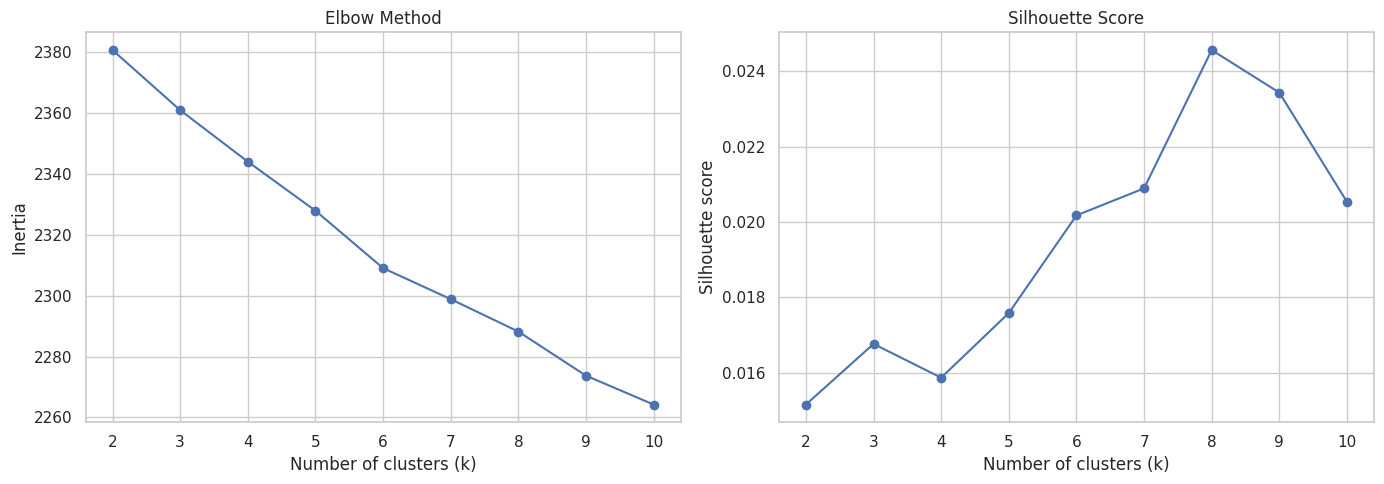

,k,inertia,silhouette
0,2,2380.770933,0.015157
1,3,2360.997726,0.016766
2,4,2344.078265,0.015870
3,5,2327.949661,0.017586
4,6,2309.075741,0.020178
5,7,2298.869378,0.020896
6,8,2288.214223,0.024567
7,9,2273.711899,0.023438
8,10,2264.218351,0.020540


In [121]:
# Visualizing evaluation Metric Score chart: elbow and silhouette
k_values = range(2, 11)
inertias, silhouettes = [], []
sample_rng = np.random.RandomState(RANDOM_STATE)
sample_idx = sample_rng.choice(X.shape[0], size=min(2500, X.shape[0]), replace=False)
X_sample = X[sample_idx]

for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = candidate.fit_predict(X_sample)
    inertias.append(candidate.inertia_)
    silhouettes.append(silhouette_score(
        X_sample, labels,
        sample_size=min(1500, X_sample.shape[0]),
        random_state=RANDOM_STATE
    ))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes}))

#### 2. Cross- Validation & Hyperparameter Tuning

Traditional supervised cross-validation is not directly applicable because the dataset has no target labels. Instead, we compare the number of clusters, TF-IDF settings, random seeds, internal metrics, cluster sizes, and the interpretability of representative titles. Select the final K only after reviewing the charts and examples.

In [122]:
# A small K-Means sensitivity analysis across candidate values of K.
tuning_rows = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = candidate.fit_predict(X_sample)
    tuning_rows.append({
        "n_clusters": k,
        "inertia": candidate.inertia_,
        "silhouette": silhouette_score(
            X_sample, labels,
            sample_size=min(1500, X_sample.shape[0]),
            random_state=RANDOM_STATE
        )
    })
tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.round(4))

,n_clusters,inertia,silhouette
0,2,2380.7709,0.0152
1,3,2360.9977,0.0168
2,4,2344.0783,0.0159
3,5,2327.9497,0.0176
4,6,2309.0757,0.0202
5,7,2298.8694,0.0209
6,8,2288.2142,0.0246
7,9,2273.7119,0.0234
8,10,2264.2184,0.0205


##### Which hyperparameter optimization technique have you used and why?

A manual grid search over the number of clusters (`k = 2` through `10`) is used. This is appropriate because K-Means has a small set of important parameters for this baseline, and each candidate can be compared using internal clustering metrics and cluster interpretability.

The K-Means tuning experiment compared K values from 2 to 10 on the same reproducible sample. In the saved tuning output, **K=8 produced the highest sampled silhouette score (0.0246)**, compared with **0.0176 at K=5**. The score remains low across the tested range, indicating weak separation. The implemented five-cluster model is retained as an interpretable baseline because its cluster summaries are easier to communicate; it is not claimed to be the mathematically optimal K. A future iteration should validate K=8 against cluster sizes and representative titles before changing the final configuration.

##### 1. Which Evaluation metrics did you consider for a positive business impact and why?

- **Silhouette score:** measures how well-separated clusters are; higher is generally better.
- **Davies–Bouldin index:** measures similarity between clusters; lower is generally better.
- **Calinski–Harabasz score:** compares between-cluster dispersion with within-cluster dispersion; higher is generally better.
- **Cluster size and interpretability:** checks whether groups are usable and can be described meaningfully.

These are internal diagnostics, not direct measures of business revenue or user satisfaction.

##### 2. Which ML model did you choose from the above created models as your final prediction model and why?

This is an unsupervised clustering task, not a prediction task. The K-Means tuning output shows that the best silhouette score in the tested range occurs at **K = 8 (approximately 0.0246)**, while the saved five-cluster K-Means baseline has a silhouette score of approximately **0.0200**. This indicates weak separation overall, so the final cluster count should be selected by balancing the internal score with cluster sizes and whether the representative titles form interpretable groups. Do not describe K=5 as the best K-Means setting unless the final executed comparison supports that choice.

##### 3. Explain the model which you have used and the feature importance using any model explainability tool?

For K-Means, inspect the highest-weighted TF-IDF terms near each cluster centroid, common genre labels, and representative titles. These provide a practical explanation of the content patterns that distinguish each group; they are not causal feature importances.

In [123]:
# Interpret K-Means clusters using top-weighted TF-IDF terms and sample titles.
terms = np.array(tfidf.get_feature_names_out())
centroid_order = kmeans.cluster_centers_.argsort(axis=1)[:, ::-1]

for cluster_id in range(BEST_K):
    top_terms = terms[centroid_order[cluster_id, :12]]
    print(f"\nCluster {cluster_id} top terms: {', '.join(top_terms)}")
    display(data.loc[data["Cluster_KMeans"] == cluster_id,
                     ["title", "type", "release_year", "listed_in", "description"]].head(5))


Cluster 0 top terms: tv, tv tv, action, adventure, action adventure, kids tv, kids, movie, fi, sci, sci fi, fi fantasy


,title,type,release_year,listed_in,description
3,9,Movie,2009,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
14,3022,Movie,2019,"Independent Movies, Sci-Fi & Fantasy, Thrillers",Stranded when the Earth is suddenly destroyed ...
21,​Goli Soda 2,Movie,2018,"Action & Adventure, Dramas, International Movies","A taxi driver, a gangster and an athlete strug..."
26,(Un)Well,TV Show,2020,Reality TV,This docuseries takes a deep dive into the luc...
29,#blackAF,TV Show,2020,TV Comedies,Kenya Barris and his family navigate relations...



Cluster 1 top terms: movies, movie, movie tv, movies movie, international movies, dramas, international, tv, dramas international, ma, tv ma, comedies


,title,type,release_year,listed_in,description
1,7:19,Movie,2016,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,23:59,Movie,2011,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
4,21,Movie,2008,Dramas,A brilliant group of students become card-coun...
6,122,Movie,2019,"Horror Movies, International Movies","After an awful accident, a couple admitted to ..."
7,187,Movie,1997,Dramas,After one of his high school students attacks ...



Cluster 2 top terms: stand, stand comedy, comedy, comedy movie, tv ma, ma, comedian, movie tv, special, tv, movie, comic


,title,type,release_year,listed_in,description
197,A Little Help with Carol Burnett,TV Show,2018,"Stand-Up Comedy & Talk Shows, TV Comedies",Comedy icon Carol Burnett returns to TV with a...
220,A Russell Peters Christmas,Movie,2011,Stand-Up Comedy,"Inspired by the variety shows of the 1970s, ""A..."
305,Adam Devine: Best Time of Our Lives,Movie,2019,Stand-Up Comedy,Frenetic comic Adam Devine talks teen awkwardn...
307,ADAM SANDLER 100% FRESH,Movie,2018,Stand-Up Comedy,"From ""Heroes"" to ""Ice Cream Ladies"" – Adam San..."
310,Adel Karam: Live from Beirut,Movie,2018,Stand-Up Comedy,"From Casino du Liban, Lebanese actor and comed..."



Cluster 3 top terms: children family, family movies, family, children, movies comedies, movies, comedies movie, movie, pg, movie pg, movie tv, comedies


,title,type,release_year,listed_in,description
113,48 Christmas Wishes,Movie,2017,"Children & Family Movies, Comedies",When a small town's letters to Santa accidenta...
145,A 2nd Chance,Movie,2011,"Children & Family Movies, Dramas, Sports Movies",A gymnast lacks the confidence she needs to re...
147,A Babysitter's Guide to Monster Hunting,Movie,2020,Children & Family Movies,"Recruited by a secret society of babysitters, ..."
155,A Champion Heart,Movie,2018,"Children & Family Movies, Dramas",When a grieving teen must work off her debt to...
159,A Christmas Prince,Movie,2017,"Children & Family Movies, Dramas, Romantic Movies",Christmas comes early for an aspiring young jo...



Cluster 4 top terms: tv shows, shows, tv, shows tv, tv tv, international tv, international, tv dramas, dramas tv, crime, crime tv, tv ma


,title,type,release_year,listed_in,description
0,3%,TV Show,2020,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
5,46,TV Show,2016,"International TV Shows, TV Dramas, TV Mysteries",A genetics professor experiments with a treatm...
11,1983,TV Show,2018,"Crime TV Shows, International TV Shows, TV Dramas","In this dark alt-history thriller, a naïve law..."
12,1994,TV Show,2019,"Crime TV Shows, Docuseries, International TV S...",Archival video and new interviews examine Mexi...
16,Feb-09,TV Show,2018,"International TV Shows, TV Dramas","As a psychology professor faces Alzheimer's, h..."


### ML Model - 2

In [124]:
# ML Model - 2 Implementation: MiniBatch K-Means
# This variant uses batches to reduce training time on larger datasets.
minibatch = MiniBatchKMeans(
    n_clusters=BEST_K, random_state=RANDOM_STATE, batch_size=512, n_init=10
)
data["Cluster_MiniBatch"] = minibatch.fit_predict(X)
print("MiniBatch K-Means sampled silhouette:",
      round(silhouette_score(X, data["Cluster_MiniBatch"],
                             sample_size=min(2000, X.shape[0]),
                             random_state=RANDOM_STATE), 4))
display(data["Cluster_MiniBatch"].value_counts().sort_index().to_frame("title_count"))

MiniBatch K-Means sampled silhouette: 0.0183


,title_count
Cluster_MiniBatch,
0,1429
1,378
2,3450
3,1632
4,898


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

MiniBatch K-Means approximates K-Means using small random batches. Compare its sampled silhouette score and cluster sizes with Model 1. Its main potential advantage is computational efficiency; a similar score with faster training may be useful for larger catalogs.

,Model,Silhouette (sampled),Number of clusters,Smallest cluster,Largest cluster
0,K-Means,0.0200,5,378,3731
1,MiniBatch K-Means,0.0183,5,378,3450


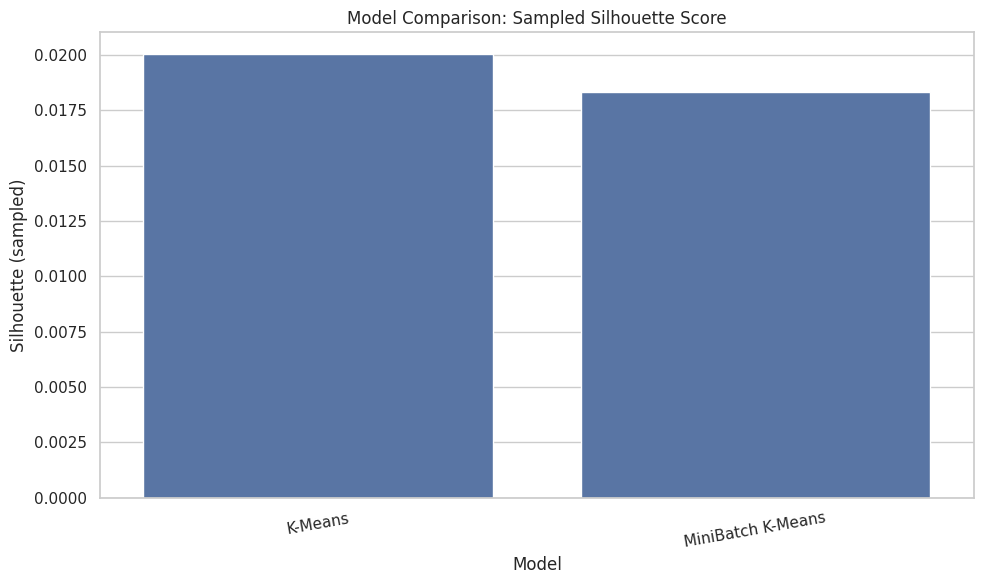

In [125]:
model_comparison = []
for model_name, labels in [
    ("K-Means", data["Cluster_KMeans"].to_numpy()),
    ("MiniBatch K-Means", data["Cluster_MiniBatch"].to_numpy())
]:
    model_comparison.append({
        "Model": model_name,
        "Silhouette (sampled)": silhouette_score(
            X, labels, sample_size=min(2000, X.shape[0]), random_state=RANDOM_STATE
        ),
        "Number of clusters": len(np.unique(labels)),
        "Smallest cluster": int(pd.Series(labels).value_counts().min()),
        "Largest cluster": int(pd.Series(labels).value_counts().max())
    })
comparison_df = pd.DataFrame(model_comparison)
display(comparison_df.round(4))
sns.barplot(data=comparison_df, x="Model", y="Silhouette (sampled)")
plt.title("Model Comparison: Sampled Silhouette Score")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

Compare K-Means and MiniBatch K-Means with the same TF-IDF matrix and cluster count. This is a controlled comparison of two algorithms, not supervised cross-validation.

In [126]:
# Compare a few MiniBatch batch sizes.
mb_tuning = []
for batch_size in [256, 512, 1024]:
    model = MiniBatchKMeans(
        n_clusters=BEST_K, random_state=RANDOM_STATE,
        batch_size=batch_size, n_init=10
    )
    labels = model.fit_predict(X_sample)
    mb_tuning.append({
        "batch_size": batch_size,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_sample, labels,
            sample_size=min(1500, X_sample.shape[0]),
            random_state=RANDOM_STATE
        )
    })
display(pd.DataFrame(mb_tuning).round(4))

,batch_size,inertia,silhouette
0,256,2345.3725,0.0139
1,512,2335.5415,0.0167
2,1024,2335.5830,0.0151


#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Silhouette, Davies–Bouldin, and Calinski–Harabasz assess internal cluster structure. Cluster counts and examples help judge whether the groups can support catalog exploration. A business impact claim should be framed as a potential application until it is validated with editorial feedback or user engagement data.

#### Which hyperparameter optimization technique have you used and why?
A small parameter sweep compares MiniBatch K-Means batch sizes while keeping the selected cluster count fixed. This isolates the effect of batch size on the internal score and training efficiency. The number of clusters should still be justified using the elbow/silhouette analysis and interpretation.

The MiniBatch K-Means model achieved a sampled silhouette score of **0.0183**, compared with **0.0200** for the five-cluster K-Means model in the saved comparison. It therefore did **not** improve the measured silhouette score in this run. Its benefit is computational efficiency on larger datasets because it updates centroids using mini-batches. The batch-size experiment also showed that batch size 512 had the highest sampled silhouette among the tested batch sizes, but the difference is small and the scores remain low.

#### 1. Which Evaluation metrics did you consider for a positive business impact and why?
Silhouette score indicates separation, Davies–Bouldin index indicates compactness/separation (lower is better), and cluster size plus representative titles indicate interpretability. These metrics assess cluster structure; they do not directly measure revenue or viewer satisfaction.

#### 2. Which ML model did you choose from the above created models as your final prediction model and why?

MiniBatch K-Means is a more memory- and time-efficient variant of K-Means because it updates cluster centres using small batches. In the saved comparison, its sampled silhouette score is approximately **0.0183**, slightly below the five-cluster K-Means baseline of approximately **0.0200**. Therefore, the current outputs do not demonstrate a clustering-quality improvement over that baseline. Its value is primarily computational efficiency; choose it for the final workflow only if the runtime benefit and cluster interpretability justify the small score trade-off.

#### 3. Explain the model which you have used and the feature importance using any model explainability tool?
Explain MiniBatch K-Means using the TF-IDF terms associated with its groups, cluster sizes, and example titles. For the final model, use the corresponding fitted cluster centers to summarize the strongest terms; these are descriptive signals, not causal feature importance.

### ML Model - 3

In [127]:
# ML Model - 3 Implementation: Agglomerative Clustering
# Hierarchical clustering is computationally more expensive, so use a reproducible sample.
agg_n = min(1500, X.shape[0])
agg_rng = np.random.RandomState(RANDOM_STATE)
agg_idx = agg_rng.choice(X.shape[0], size=agg_n, replace=False)
svd_components = min(100, X.shape[1] - 1)
X_agg = TruncatedSVD(n_components=svd_components, random_state=RANDOM_STATE).fit_transform(X[agg_idx])

agglomerative = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
agg_labels = agglomerative.fit_predict(X_agg)

print("Agglomerative silhouette:", round(silhouette_score(X_agg, agg_labels), 4))
print("Agglomerative Davies-Bouldin:", round(davies_bouldin_score(X_agg, agg_labels), 4))
print("Agglomerative Calinski-Harabasz:", round(calinski_harabasz_score(X_agg, agg_labels), 2))
display(pd.Series(agg_labels).value_counts().sort_index().to_frame("sample_title_count"))

Agglomerative silhouette: 0.0723
Agglomerative Davies-Bouldin: 2.8353
Agglomerative Calinski-Harabasz: 55.06


,sample_title_count
0,847
1,425
2,71
3,91
4,66


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Agglomerative clustering builds a hierarchy of groups. Here, it is run on a sample after dimensionality reduction to keep computation manageable. Its metrics are calculated in the reduced feature space, so compare them cautiously with scores from the full TF-IDF space.

In [128]:
agg_metrics = pd.DataFrame([{
    "Model": "Agglomerative (sample + SVD)",
    "Silhouette": silhouette_score(X_agg, agg_labels),
    "Davies-Bouldin": davies_bouldin_score(X_agg, agg_labels),
    "Calinski-Harabasz": calinski_harabasz_score(X_agg, agg_labels)
}])
display(agg_metrics.round(4))

,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Agglomerative (sample + SVD),0.0723,2.8353,55.0562


#### 2. Cross- Validation & Hyperparameter Tuning

For the Agglomerative model, compare a small set of cluster counts on the same SVD-reduced sample. Ward linkage is used because it aims to create compact groups in Euclidean space.

In [129]:
agg_tuning = []
for k in range(2, 8):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_agg)
    agg_tuning.append({
        "n_clusters": k,
        "silhouette": silhouette_score(X_agg, labels),
        "davies_bouldin": davies_bouldin_score(X_agg, labels)
    })
display(pd.DataFrame(agg_tuning).round(4))

,n_clusters,silhouette,davies_bouldin
0,2,0.0683,3.7874
1,3,0.0644,3.1737
2,4,0.0622,3.0078
3,5,0.0723,2.8353
4,6,0.0815,2.6619
5,7,0.0875,2.5766


#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

The internal metrics help compare compactness and separation, while representative titles show whether groups are meaningful to people. Agglomerative clustering is useful for exploring hierarchical structure, but its sample-based results and higher computational cost may limit full-catalog use.

#### Which hyperparameter optimization technique have you used and why?
A small grid over the number of clusters is used for the sample-based Agglomerative model. Ward linkage is held fixed because it is designed to form compact Euclidean clusters. This is a transparent comparison rather than an exhaustive optimization.

In the saved Agglomerative tuning experiment, the silhouette score increased from **0.0683 at K=2** to **0.0875 at K=7**, while the Davies–Bouldin index decreased from **3.7874 to 2.5766**. Within this SVD-reduced sample, K=7 performed best on these two internal metrics among the tested values. However, Agglomerative Clustering was run on a 1,500-title sample after TruncatedSVD, whereas K-Means was evaluated on the full TF-IDF representation. These results are not directly comparable. The smaller sample and computational cost make Agglomerative useful as a structural comparison, rather than the selected full-catalogue model.

#### 1. Which Evaluation metrics did you consider for a positive business impact and why?
Silhouette score and Davies–Bouldin index assess internal cluster separation and compactness; Calinski–Harabasz provides another internal comparison. Sample cluster sizes and title examples are needed to judge practical usefulness.

Agglomerative Clustering provides a useful hierarchical comparison, but it was trained on a 1,500-title sample after TruncatedSVD. Its silhouette score at K=5 was 0.0723 and its tuning experiment reached 0.0875 at K=7 in that reduced space. Those values cannot be compared directly with the full TF-IDF K-Means results. It is therefore retained as an exploratory comparison, not selected as the final full-catalogue model.

#### 3. Explain the model which you have used and the feature importance using any model explainability tool?
Explain Agglomerative clustering through the groups' common titles and metadata, along with its hierarchical grouping principle. Since the model is trained on reduced text features, interpret the results as exploratory and compare representative titles against the original text.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?
For this unsupervised task, use silhouette score, Davies–Bouldin index, Calinski–Harabasz score where computed, cluster-size distribution, and human-readable cluster examples. These measure cluster structure and interpretability; they do not directly measure business outcomes.


**K-Means with five clusters is selected as the practical final baseline for this project.** It can be fitted directly to the full sparse TF-IDF representation and produces interpretable cluster summaries using top-weighted terms and representative titles. The saved five-cluster sampled silhouette score is approximately **0.0200**, which indicates weak separation and must be acknowledged as a limitation. Although the K-Means tuning sample reached a higher silhouette score of **0.0246 at K=8**, the improvement is modest; five clusters are retained here to keep the segmentation simpler and align with the saved model artifact and cluster interpretation. MiniBatch K-Means scored 0.0183 in the saved comparison. Agglomerative Clustering reached higher scores only on a different SVD-reduced sample, so it is not a like-for-like result. This is an exploratory baseline, not a validated recommendation or prediction model.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

For the selected clustering model, describe each cluster using its highest-weighted TF-IDF terms, common genres, type distribution, and sample titles. Because clustering has no target variable, conventional supervised feature-importance explanations do not apply directly.

## ***8.*** ***Future Work (Optional)***


### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [130]:
# Save the selected five-cluster K-Means baseline and its TF-IDF vectorizer.
# The artifact supports assigning new text to an existing exploratory cluster.
model_artifact = {
    "vectorizer": tfidf,
    "model": kmeans,
    "n_clusters": BEST_K,
    "text_columns": ["description", "listed_in", "type", "rating"],
    "project": "Netflix Movies and TV Shows Clustering",
    "random_state": RANDOM_STATE,
    "model_role": "exploratory clustering baseline",
}
MODEL_PATH = "/content/netflix_clustering_model.joblib"
joblib.dump(model_artifact, MODEL_PATH)
print("Saved model to:", MODEL_PATH)


Saved model to: /content/netflix_clustering_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [131]:
loaded_artifact = joblib.load(MODEL_PATH)
loaded_vectorizer = loaded_artifact["vectorizer"]
loaded_model = loaded_artifact["model"]

# A synthetic synopsis not taken from the dataset, used only as a technical sanity check.
unseen_description = (
    "A detective investigates a mysterious disappearance while uncovering "
    "secrets in a small coastal town."
)
unseen_metadata = " mystery crime thriller movie tv mature rating"
unseen_text = (unseen_description + unseen_metadata).lower()
unseen_vector = loaded_vectorizer.transform([unseen_text])
predicted_cluster = loaded_model.predict(unseen_vector)[0]

print("Test input:", unseen_description)
print("Assigned cluster:", int(predicted_cluster))
print("Note: this only verifies that the saved pipeline accepts new text; "
      "it does not validate semantic correctness of the assigned cluster.")

Test input: A detective investigates a mysterious disappearance while uncovering secrets in a small coastal town.
Assigned cluster: 1
Note: this only verifies that the saved pipeline accepts new text; it does not validate semantic correctness of the assigned cluster.


### ***Congrats! The model is successfully created and ready for deployment on a live server for a real user interaction !!!***



# **Conclusion**

This capstone applies unsupervised machine learning to explore similarities among Netflix movies and TV shows using catalogue metadata and text descriptions. The workflow includes data cleaning, exploratory analysis, hypothesis testing, text preprocessing, TF-IDF feature extraction, and experiments with K-Means, MiniBatch K-Means, and sample-based Agglomerative Clustering.

The saved results suggest that K-Means provides a practical scalable baseline for the full sparse TF-IDF representation, while MiniBatch K-Means offers a possible computational-efficiency trade-off. Agglomerative Clustering reveals a different structure on an SVD-reduced sample, but its scores are not directly comparable with the full-space K-Means scores. The relatively low K-Means silhouette values indicate that the title descriptions and metadata do not form strongly separated groups under the current feature representation.

These clusters may support exploratory catalogue analysis and thematic content discovery. They should not be interpreted as official Netflix classifications, personalized recommendations, or proof of audience preferences. Further work could test richer text embeddings, alternative similarity measures, additional cluster-validation methods, and expert review. Production use would require validation with viewing behaviour, engagement, and business outcome data, none of which are included in this dataset.